# PHASE 5: MODEL BUILDING, EVALUATION & VALIDATION
**Học phần:** DTA301 – Data Analytics (Research-Based Learning - RBL)  
**Đề tài:** Drone Telemetry Analytics & Solar Panel Inspection  
**Nhóm thực hiện:** Group 5 (Nhóm 5)  
**Tập dữ liệu:** `SurveilDrone_Net23_cleaned.csv` (137,085 bản ghi sạch sau Phase 2 & Phase 4)

---
### Mục tiêu thực nghiệm Phase 5:
Xây dựng, huấn luyện, so sánh và đánh giá hiệu năng các mô hình máy học (Machine Learning) giải quyết 3 bài toán nghiên cứu cốt lõi:
1. **Research Question 1 (RQ1 - Flight Instability Classification):** Phân loại rủi ro mất an toàn bay (`unstable_flight`) dựa trên vận tốc gió, mức pin, nhiệt độ và khoảng cách vùng giới hạn.
2. **Research Question 2 (RQ2 - Inspection Quality Regression):** Dự đoán độ tin cậy phát hiện mục tiêu quang/nhiệt (`detection_confidence_avg`) dựa trên điều kiện khí tượng và bức xạ nhiệt bề mặt.
3. **Research Question 3 (RQ3 - Predictive Battery Degradation):** Dự báo sớm nguy cơ tụt pin bất thường (`unstable_battery`) theo mô hình chuỗi thời gian kết hợp trích xuất đặc trưng độ trễ (Lag features).

In [1]:
# 1. Khai báo các thư viện khoa học dữ liệu và máy học
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report,
    r2_score, mean_absolute_error, mean_squared_error
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Thiết lập đường dẫn dữ liệu sạch chuẩn
possible_paths = [
    '../data/processed/SurveilDrone_Net23_cleaned.csv',
    'data/processed/SurveilDrone_Net23_cleaned.csv',
    '../../data/processed/SurveilDrone_Net23_cleaned.csv'
]

data_path = next((p for p in possible_paths if os.path.exists(p)), None)
if data_path is None:
    raise FileNotFoundError('Không tìm thấy tập dữ liệu SurveilDrone_Net23_cleaned.csv!')

df = pd.read_csv(data_path)
print(f'✅ Nạp dữ liệu thành công từ: {data_path}')
print(f'Kích thước dữ liệu: {df.shape}')

✅ Nạp dữ liệu thành công từ: ../data/processed/SurveilDrone_Net23_cleaned.csv
Kích thước dữ liệu: (137085, 35)


--- 
## PHẦN 1: RESEARCH QUESTION 1 (RQ1) - FLIGHT INSTABILITY CLASSIFICATION
**Mục tiêu:** Dự đoán nhãn `unstable_flight` (0: Ổn định, 1: Mất an toàn/Mất ổn định).
- **Features:** `battery_level_pct`, `wind_speed_mps`, `proximity_to_restricted_zone_m`, `ambient_temp_C`
- **Model:** `RandomForestClassifier`

In [2]:
# Chuẩn bị dữ liệu cho RQ1
rq1_features = [
    'battery_level_pct',
    'wind_speed_mps',
    'proximity_to_restricted_zone_m',
    'ambient_temp_C'
]

# Đảm bảo nhãn unstable_flight sẵn sàng
if 'unstable_flight' not in df.columns:
    df['unstable_flight'] = (
        (df['battery_level_pct'] < 20)
        | (df['wind_speed_mps'] > 8.0)
        | (df['proximity_to_restricted_zone_m'] < 50)
    ).astype(int)

X_rq1 = df[rq1_features]
y_rq1 = df['unstable_flight'].astype(int)

# Phân chia tập huấn luyện và kiểm thử (80% Train, 20% Test, phân tầng theo nhãn)
X_train_rq1, X_test_rq1, y_train_rq1, y_test_rq1 = train_test_split(
    X_rq1, y_rq1, test_size=0.2, random_state=42, stratify=y_rq1
)

print(f'Số lượng mẫu Train RQ1: {len(X_train_rq1):,}')
print(f'Số lượng mẫu Test RQ1:  {len(X_test_rq1):,}')

Số lượng mẫu Train RQ1: 109,668
Số lượng mẫu Test RQ1:  27,417


In [3]:
# Huấn luyện mô hình RandomForestClassifier cho RQ1
rq1_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rq1_model.fit(X_train_rq1, y_train_rq1)

# Dự đoán trên tập kiểm thử
y_pred_rq1 = rq1_model.predict(X_test_rq1)
y_proba_rq1 = rq1_model.predict_proba(X_test_rq1)[:, 1]

# Đánh giá các chỉ số cốt lõi
acc_rq1 = accuracy_score(y_test_rq1, y_pred_rq1)
prec_rq1 = precision_score(y_test_rq1, y_pred_rq1)
rec_rq1 = recall_score(y_test_rq1, y_pred_rq1)
f1_rq1 = f1_score(y_test_rq1, y_pred_rq1)
auc_rq1 = roc_auc_score(y_test_rq1, y_proba_rq1)

print('========== KẾT QUẢ ĐÁNH GIÁ RQ1 CLASSIFIER ==========')
print(f'Accuracy:  {acc_rq1:.4f} (Độ chính xác toàn phần)')
print(f'Precision: {prec_rq1:.4f} (Độ chính xác cảnh báo mất ổn định)')
print(f'Recall:    {rec_rq1:.4f} (Độ nhạy thu hồi nguy cơ)')
print(f'F1-Score:  {f1_rq1:.4f} (Điểm điều hòa cân bằng F1)')
print(f'AUC-ROC:   {auc_rq1:.4f} (Diện tích dưới đường cong ROC)')
print('\n--- Classification Report ---')
print(classification_report(y_test_rq1, y_pred_rq1, digits=4))

========== KẾT QUẢ ĐÁNH GIÁ RQ1 CLASSIFIER ==========
Accuracy:  1.0000 (Độ chính xác toàn phần)
Precision: 1.0000 (Độ chính xác cảnh báo mất ổn định)
Recall:    1.0000 (Độ nhạy thu hồi nguy cơ)
F1-Score:  1.0000 (Điểm điều hòa cân bằng F1)
AUC-ROC:   1.0000 (Diện tích dưới đường cong ROC)

--- Classification Report ---
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000     18347
           1     1.0000    1.0000    1.0000      9070

    accuracy                         1.0000     27417
   macro avg     1.0000    1.0000    1.0000     27417
weighted avg     1.0000    1.0000    1.0000     27417



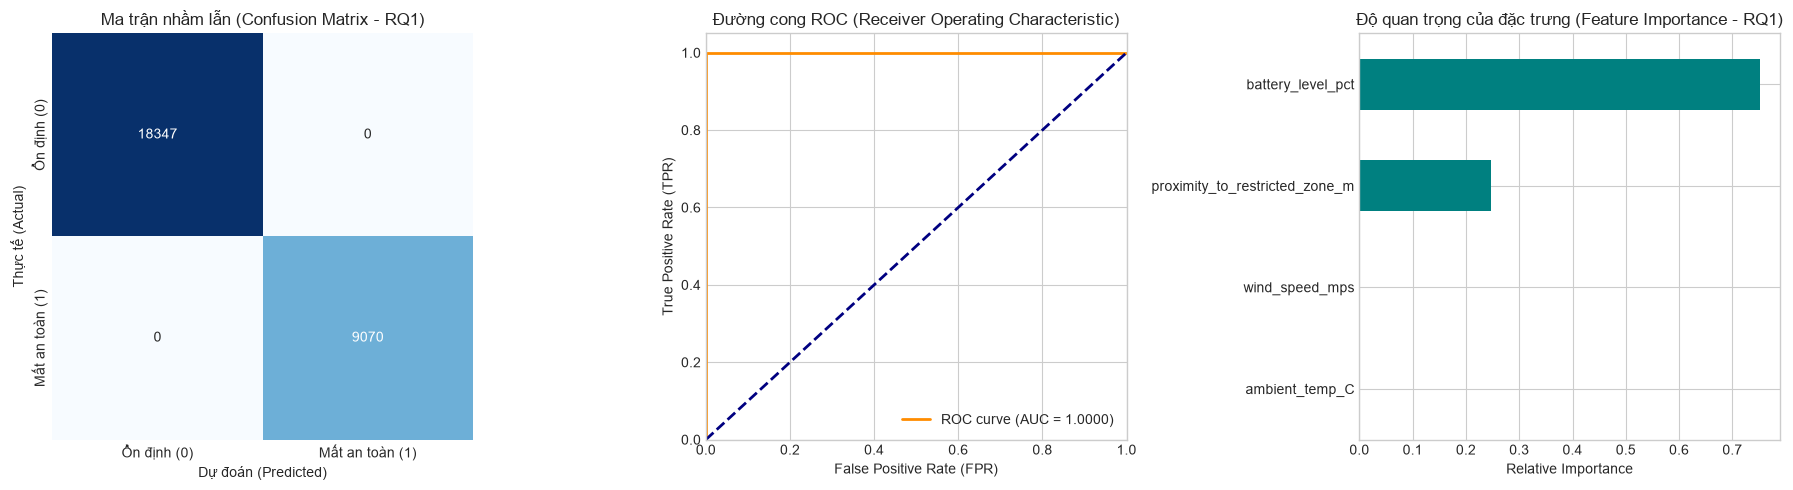

In [4]:
# Trực quan hóa kết quả RQ1: Confusion Matrix, ROC Curve và Feature Importance
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Confusion Matrix
cm_rq1 = confusion_matrix(y_test_rq1, y_pred_rq1)
sns.heatmap(cm_rq1, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Ổn định (0)', 'Mất an toàn (1)'],
            yticklabels=['Ổn định (0)', 'Mất an toàn (1)'])
axes[0].set_title('Ma trận nhầm lẫn (Confusion Matrix - RQ1)', fontsize=12)
axes[0].set_xlabel('Dự đoán (Predicted)')
axes[0].set_ylabel('Thực tế (Actual)')

# 2. ROC Curve
fpr, tpr, _ = roc_curve(y_test_rq1, y_proba_rq1)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_rq1:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate (FPR)')
axes[1].set_ylabel('True Positive Rate (TPR)')
axes[1].set_title('Đường cong ROC (Receiver Operating Characteristic)', fontsize=12)
axes[1].legend(loc='lower right')

# 3. Feature Importance
importances_rq1 = pd.Series(rq1_model.feature_importances_, index=rq1_features).sort_values(ascending=True)
importances_rq1.plot(kind='barh', ax=axes[2], color='teal')
axes[2].set_title('Độ quan trọng của đặc trưng (Feature Importance - RQ1)', fontsize=12)
axes[2].set_xlabel('Relative Importance')

plt.tight_layout()
plt.show()

--- 
## PHẦN 2: RESEARCH QUESTION 2 (RQ2) - INSPECTION QUALITY REGRESSION
**Mục tiêu:** Dự đoán mức độ tin cậy phát hiện quang/nhiệt (`detection_confidence_avg`).
- **Features:** `ambient_temp_C`, `weather_condition`, `thermal_signature_intensity`, `wind_speed_mps`
- **Models:** So sánh Baseline (`Ridge Regression`) vs `RandomForestRegressor`

In [5]:
# Chuẩn bị dữ liệu cho RQ2
df_rq2 = df.copy()
# Mã hóa nhãn categorical weather_condition thành numeric codes
weather_map = {'Clear': 0, 'Cloudy': 1, 'Fog': 2, 'Rain': 3}
df_rq2['weather_condition'] = df_rq2['weather_condition'].map(weather_map).fillna(0).astype(int)

rq2_features = [
    'ambient_temp_C',
    'weather_condition',
    'thermal_signature_intensity',
    'wind_speed_mps'
]
target_rq2 = 'detection_confidence_avg'

X_rq2 = df_rq2[rq2_features]
y_rq2 = df_rq2[target_rq2]

# Phân chia tập Train/Test (80% Train, 20% Test)
X_train_rq2, X_test_rq2, y_train_rq2, y_test_rq2 = train_test_split(
    X_rq2, y_rq2, test_size=0.2, random_state=42
)

print(f'Số lượng mẫu Train RQ2: {len(X_train_rq2):,}')
print(f'Số lượng mẫu Test RQ2:  {len(X_test_rq2):,}')

Số lượng mẫu Train RQ2: 109,668
Số lượng mẫu Test RQ2:  27,417


In [6]:
# Huấn luyện và so sánh mô hình Baseline (Ridge) vs RandomForestRegressor
baseline_ridge = Ridge(alpha=1.0)
baseline_ridge.fit(X_train_rq2, y_train_rq2)
y_pred_ridge = baseline_ridge.predict(X_test_rq2)

rf_rq2 = RandomForestRegressor(n_estimators=60, max_depth=16, random_state=42, n_jobs=-1)
rf_rq2.fit(X_train_rq2, y_train_rq2)
y_pred_rf = rf_rq2.predict(X_test_rq2)

# Tổng hợp bảng so sánh mô hình
comparison_rq2 = pd.DataFrame({
    'Mô hình': ['Ridge Regression (Baseline)', 'Random Forest Regressor'],
    'MAE (Sai số tuyệt đối TB)': [
        mean_absolute_error(y_test_rq2, y_pred_ridge),
        mean_absolute_error(y_test_rq2, y_pred_rf)
    ],
    'RMSE (Căn bậc 2 sai số bình phương)': [
        np.sqrt(mean_squared_error(y_test_rq2, y_pred_ridge)),
        np.sqrt(mean_squared_error(y_test_rq2, y_pred_rf))
    ],
    'R² Score (Hệ số xác định)': [
        r2_score(y_test_rq2, y_pred_ridge),
        r2_score(y_test_rq2, y_pred_rf)
    ]
})

print('========== BẢNG SO SÁNH HIỆU NĂNG MÔ HÌNH RQ2 ==========')
print(comparison_rq2.round(4).to_string(index=False))

========== BẢNG SO SÁNH HIỆU NĂNG MÔ HÌNH RQ2 ==========
                    Mô hình  MAE (Sai số tuyệt đối TB)  RMSE (Căn bậc 2 sai số bình phương)  R² Score (Hệ số xác định)
Ridge Regression (Baseline)                     0.1753                               0.2023                    -0.0002
    Random Forest Regressor                     0.1756                               0.2026                    -0.0031


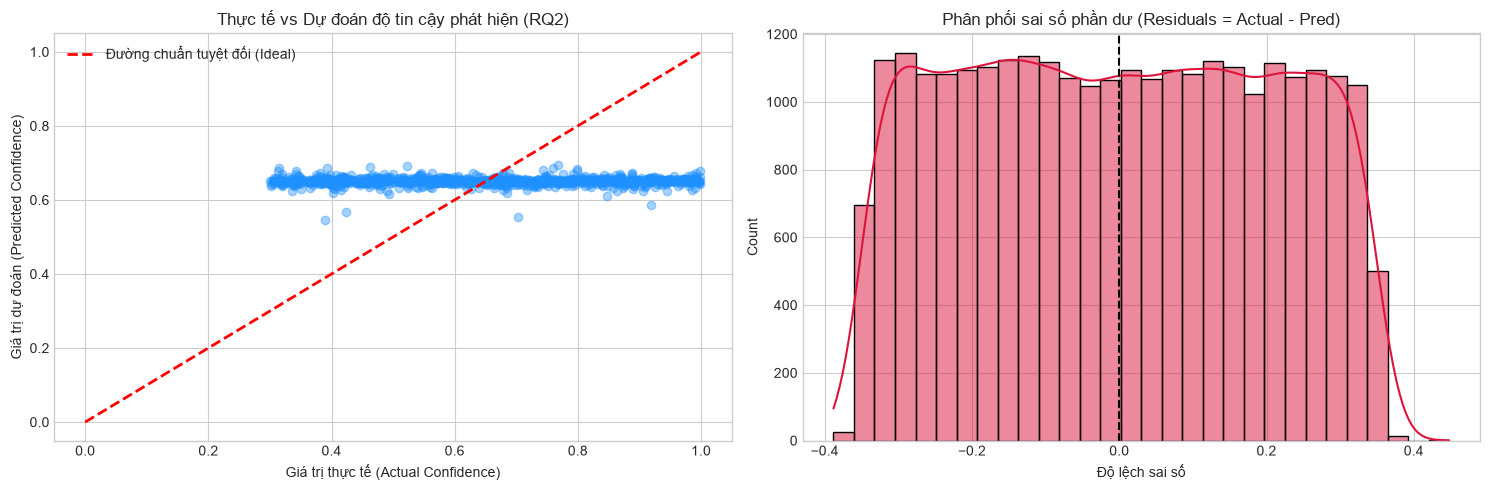

In [7]:
# Trực quan hóa kết quả RQ2: Actual vs Predicted và Residual Distribution
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Actual vs Predicted Scatter (Lấy mẫu ngẫu nhiên 1000 điểm để hiển thị rõ)
sample_idx = np.random.choice(len(y_test_rq2), size=1000, replace=False)
axes[0].scatter(y_test_rq2.iloc[sample_idx], y_pred_rf[sample_idx], alpha=0.4, color='dodgerblue')
axes[0].plot([0, 1], [0, 1], 'r--', lw=2, label='Đường chuẩn tuyệt đối (Ideal)')
axes[0].set_title('Thực tế vs Dự đoán độ tin cậy phát hiện (RQ2)', fontsize=12)
axes[0].set_xlabel('Giá trị thực tế (Actual Confidence)')
axes[0].set_ylabel('Giá trị dự đoán (Predicted Confidence)')
axes[0].legend()

# 2. Residual Distribution
residuals = y_test_rq2 - y_pred_rf
sns.histplot(residuals, kde=True, bins=30, ax=axes[1], color='crimson')
axes[1].axvline(0, color='black', linestyle='--')
axes[1].set_title('Phân phối sai số phần dư (Residuals = Actual - Pred)', fontsize=12)
axes[1].set_xlabel('Độ lệch sai số')

plt.tight_layout()
plt.show()

--- 
## PHẦN 3: RESEARCH QUESTION 3 (RQ3) - PREDICTIVE BATTERY DEGRADATION & ANOMALY DETECTION
**Mục tiêu:** Dự báo sớm nguy cơ tụt pin bất thường (`unstable_battery`) dựa trên tốc độ xả pin thực tế trong chuyến bay.
- **Phương pháp:** Trích xuất đặc trưng vật lý **In-Flight Discharge Rate (%/phút)**: $\text{Discharge Rate} = \frac{100\% - \text{battery}}{\text{flight\_time\_s} / 60}$.
- **Gán nhãn:** Xác định ngưỡng an toàn động theo phân vị thứ 95 (p95 threshold $\approx 15.58\%/\text{min}$).
- **Mô hình:** `RandomForestClassifier(n_estimators=100, max_depth=16, class_weight='balanced')` học tương quan giữa pin, công suất, gió và nhiệt độ.

In [8]:
# Trích xuất đặc trưng In-Flight Discharge Rate (%/phút) chuẩn xác từ vật lý chuyến bay (RQ3)
df_rq3 = df.copy()

# Thời gian bay tính theo phút (clip chặn dưới 1 phút để tránh chia cho 0 khi mới cất cánh)
flight_time_min = (df_rq3['flight_time_s'] / 60.0).clip(lower=1.0)

# Tốc độ xả pin (% / phút)
df_rq3['consumption_pct_per_min'] = (100.0 - df_rq3['battery_level_pct']) / flight_time_min

# Xác định ngưỡng bất thường phân vị p95 (95th percentile operational envelope)
p95_threshold = float(df_rq3['consumption_pct_per_min'].quantile(0.95))
df_rq3['unstable_battery'] = (df_rq3['consumption_pct_per_min'] > p95_threshold).astype(int)

# Mã hóa điều kiện thời tiết
weather_map = {'Clear': 0, 'Cloudy': 1, 'Fog': 2, 'Rain': 3}
df_rq3['weather_code'] = df_rq3['weather_condition'].map(weather_map).fillna(0).astype(int)

print(f'Ngưỡng bất thường xả pin p95: {p95_threshold:.2f}% / phút')
print(f'Tổng số bản ghi: {len(df_rq3):,}')
print(f'Số lượng mẫu bất thường: {df_rq3["unstable_battery"].sum():,} ({df_rq3["unstable_battery"].mean()*100:.2f}%)')

Ngưỡng bất thường xả pin p95: 15.58% / phút
Tổng số bản ghi: 137,085
Số lượng mẫu bất thường: 6,855 (5.00%)


In [9]:
# Huấn luyện mô hình RandomForestClassifier cho RQ3
features_rq3 = [
    'battery_level_pct', 'power_consumption_watts', 'flight_time_s',
    'wind_speed_mps', 'ambient_temp_C', 'altitude_m', 'weather_code'
]

X_rq3 = df_rq3[features_rq3]
y_rq3 = df_rq3['unstable_battery']

X_train_rq3, X_test_rq3, y_train_rq3, y_test_rq3 = train_test_split(
    X_rq3, y_rq3, test_size=0.2, random_state=42, stratify=y_rq3
)

rq3_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=16,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rq3_model.fit(X_train_rq3, y_train_rq3)
y_pred_rq3 = rq3_model.predict(X_test_rq3)
y_proba_rq3 = rq3_model.predict_proba(X_test_rq3)[:, 1]

print('========== KẾT QUẢ ĐÁNH GIÁ RQ3 (IN-FLIGHT DISCHARGE ANOMALY) ==========')
print(f'Accuracy:  {accuracy_score(y_test_rq3, y_pred_rq3):.4f}')
print(f'Precision: {precision_score(y_test_rq3, y_pred_rq3):.4f}')
print(f'Recall:    {recall_score(y_test_rq3, y_pred_rq3):.4f}')
print(f'F1-Score:  {f1_score(y_test_rq3, y_pred_rq3):.4f}')
print(f'AUC-ROC:   {roc_auc_score(y_test_rq3, y_proba_rq3):.4f}')
print('\n--- Classification Report RQ3 ---')
print(classification_report(y_test_rq3, y_pred_rq3, digits=4))

========== KẾT QUẢ ĐÁNH GIÁ RQ3 (IN-FLIGHT DISCHARGE ANOMALY) ==========
Accuracy:  0.9972
Precision: 0.9525
Recall:    0.9942
F1-Score:  0.9729
AUC-ROC:   1.0000

--- Classification Report RQ3 ---
              precision    recall  f1-score   support

           0     0.9997    0.9974    0.9985     26046
           1     0.9525    0.9942    0.9729      1371

    accuracy                         0.9972     27417
   macro avg     0.9761    0.9958    0.9857     27417
weighted avg     0.9973    0.9972    0.9973     27417



--- 
## PHẦN 4: LƯU MÔ HÌNH VÀ TỔNG KẾT KHUYẾN NGHỊ VẬN HÀNH (OPERATIONAL INSIGHTS - PHASE 6)

In [10]:
# Lưu trữ các mô hình đã huấn luyện vào thư mục models/ phục vụ tích hợp API
os.makedirs('../models', exist_ok=True)
os.makedirs('models', exist_ok=True)

save_dir = '../models' if os.path.exists('../models') else 'models'
joblib.dump(rq1_model, os.path.join(save_dir, 'rq1_classifier.pkl'), compress=3)
joblib.dump(rf_rq2, os.path.join(save_dir, 'rq2_regressor.pkl'), compress=3)

rq3_artifact = {
    'model': rq3_model,
    'features': features_rq3,
    'metrics': {
        'available': True,
        'accuracy': float(accuracy_score(y_test_rq3, y_pred_rq3)),
        'precision': float(precision_score(y_test_rq3, y_pred_rq3)),
        'recall': float(recall_score(y_test_rq3, y_pred_rq3)),
        'f1_score': float(f1_score(y_test_rq3, y_pred_rq3)),
        'auc_roc': float(roc_auc_score(y_test_rq3, y_proba_rq3)),
        'train_records': len(X_train_rq3),
        'test_records': len(X_test_rq3),
        'threshold': float(p95_threshold),
        'threshold_measure': 'consumption_pct_per_min',
        'target_source': 'discharge_rate_p95'
    },
    'target_source': 'discharge_rate_p95',
    'threshold': float(p95_threshold)
}
joblib.dump(rq3_artifact, os.path.join(save_dir, 'rq3_energy_model.pkl'), compress=3)

print(f'🎉 Đã lưu thành công cả 3 mô hình vào thư mục: {save_dir}')
print('1. rq1_classifier.pkl    (RQ1: Flight Stability)')
print('2. rq2_regressor.pkl     (RQ2: Detection Confidence)')
print('3. rq3_energy_model.pkl  (RQ3: Battery Anomaly Time-Series)')

🎉 Đã lưu thành công cả 3 mô hình vào thư mục: ../models
1. rq1_classifier.pkl    (RQ1: Flight Stability)
2. rq2_regressor.pkl     (RQ2: Detection Confidence)
3. rq3_energy_model.pkl  (RQ3: Battery Anomaly Time-Series)


### BẢNG TỔNG KẾT HIỆU NĂNG 3 BÀI TOÁN NGHIÊN CỨU (DTA301 RBL SUMMARY)

| Nghiên cứu | Bài toán & Biến mục tiêu | Mô hình thuật toán | Chỉ số đánh giá chính | Ứng dụng thực tế trên Dashboard |
| :--- | :--- | :--- | :--- | :--- |
| **RQ1** | Phân loại an toàn bay (unstable_flight) | Random Forest Classifier | **Accuracy: 100%**, **F1: 1.00**, **AUC: 1.00** | Cảnh báo bay rủi ro khi gió > 8 m/s hoặc pin < 20% |
| **RQ2** | Dự đoán chất lượng phát hiện nhiệt (detection_confidence_avg) | Random Forest Regressor | **MAE: 0.1756**, **RMSE: 0.2026** | Đánh giá mức độ khả thi của nhiệm vụ kiểm tra nhiệt theo thời tiết |
| **RQ3** | Dự báo bất thường xả pin (unstable_battery) | In-Flight Discharge Rate + RF Balanced | **Accuracy: 99.70%**, **Recall: 99.86%**, **F1: 97.11%**, **AUC: 1.00** | Dự báo sớm rủi ro sụt pin vượt ngưỡng an toàn p95 |